# Histograms 

In [1]:
import pandas as pd
import openpyxl
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

import rasterio
from rasterio.windows import Window
from rasterio.errors import WindowError
from rasterio.windows import Window, from_bounds
from rasterio.features import geometry_mask
from rasterio.plot import show

import time 
from collections import Counter
import gc

import re
import math

import geopandas as gpd
import pandas as pd
import os

In [2]:
# MapBiomas class code -> name mapping
mapbiomas_classes = {
    0: "nan",
    2: "Other nat. veg.",
    3: "Forest Formation", #Native Forest for next run!
    9: "Forest Plantation",
    11: "Wetland",
    15: "Pasture",
    19: "Temporary Crops",
    22: "Non veg. area",
    27: "Not Observed",
    33: "Water",
    36: "Perennial Crops",
#    39: "Soybean",

    }

In [16]:
# Folder containing the TIFF files
folder = Path(r"C:\Users\")

# Folder containing the AOI shapefiles to run the histogram over
aoi_folder = folder / "AOI"

# Find all matching TIFF files
tiff_files = sorted(folder.glob("Reclass_img_*_v0806.tif"))
print(f"Found {len(tiff_files)} raster(s)")

Found 40 raster(s)


In [17]:
# Find all AOI shapefiles
shapefile_paths = sorted(aoi_folder.glob("*.shp"))
print(f"Found {len(shapefile_paths)} shapefile(s) in {aoi_folder}")

Found 5 shapefile(s) in C:\Users\ahuvi\Downloads\Paper_3\MapBiomas\AOI


In [20]:
# folder, tiff_files, shapefile_paths assumed already defined earlier in the notebook

# --- Manual renaming: map each shapefile's filename (without .shp) to the
# label you want used in its output table / filename. Any shapefile not
# listed here falls back to its own filename stem. Edit this dict to give
# each AOI a clean name. ---
SHAPEFILE_NAME_OVERRIDES = {
    # "raw_shapefile_stem": "Friendly Name",
    "AltoParana_adm_bound_50km_50perc_v3857": "APAF_studyarea",
    "alto_parana_3857": "APAF_ecoregion",
    "APAF_Argentina_4326": "Argentina",
    "APAF_Brazil_4326": "Brazil",
    "APAF_Paraguay_4326": "Paraguay",
}

for shp_path in shapefile_paths:

    shp_stem = shp_path.stem
    shp_label = SHAPEFILE_NAME_OVERRIDES.get(shp_stem, shp_stem)

    print(f"\n=== AOI: {shp_label} ({shp_path.name}) ===")

    aoi = gpd.read_file(shp_path)

    all_histograms = []

    # Cache the reprojected AOI geometries per raster CRS, so we only
    # reproject once even though the same CRS repeats across every year.
    reproj_cache = {}

    for tif_path in tiff_files:

        with rasterio.open(tif_path) as src:

            nodata = src.nodata
            crs_key = src.crs.to_string()

            if crs_key not in reproj_cache:
                aoi_reproj = aoi.to_crs(src.crs)
                geometries = [
                    geom for geom in aoi_reproj.geometry
                    if geom is not None and not geom.is_empty
                ]
                reproj_cache[crs_key] = geometries
            else:
                geometries = reproj_cache[crs_key]

            if not geometries:
                print(f"  Skipping {tif_path.name}: no valid geometries in {shp_label}")
                continue

            # Single crop+mask call: GDAL rasterizes the AOI polygon once and
            # reads only the intersecting window, instead of looping over
            # every raster block and re-rasterizing the polygon each time.
            try:
                clipped, clipped_transform = rio_mask(
                    src, geometries, crop=True, filled=True,
                    nodata=nodata if nodata is not None else 0
                )
            except ValueError:
                print(f"  Skipping {tif_path.name}: {shp_label} does not overlap raster")
                continue

            data = clipped[0]

            # Merge class 39 into class 19
            data[data == 39] = 19

            valid = np.ones(data.shape, dtype=bool)
            if nodata is not None:
                valid &= (data != nodata)

            values, counts = np.unique(data[valid], return_counts=True)
            counts_dict = dict(zip(values.tolist(), counts.tolist()))

            del clipped, data, valid
            gc.collect()

        # Create histogram DataFrame
        df = pd.DataFrame({
            "file": tif_path.name,
            "shapefile": shp_label,
            "value": list(counts_dict.keys()),
            "count": list(counts_dict.values())
        })

        df = df.sort_values("value").reset_index(drop=True)

        all_histograms.append(df)

        print(f"  Processed {tif_path.name}: {len(df)} unique values")

    # Skip shapefile if no data was collected
    if not all_histograms:
        print(f"  No data collected for {shp_label}, skipping output")
        continue

    # Combine histograms
    histogram_table = pd.concat(all_histograms, ignore_index=True)

    # Pivot to wide format
    histogram_wide = (
        histogram_table
        .pivot(index="value", columns="file", values="count")
        .fillna(0)
    )

    # Save CSV files
    safe_label = shp_label.replace(" ", "_")

    histogram_table.to_csv(folder / f"histograms_long_{safe_label}.csv", index=False)
    histogram_wide.to_csv(folder / f"histograms_wide_{safe_label}.csv")

    print(f"  Saved: histograms_long_{safe_label}.csv / histograms_wide_{safe_label}.csv")
    print(histogram_table.head())

print("\nDone.")


=== AOI: APAF_ecoregion (alto_parana_3857.shp) ===
  Processed Reclass_img_1985_v0806.tif: 11 unique values
  Processed Reclass_img_1986_v0806.tif: 11 unique values
  Processed Reclass_img_1987_v0806.tif: 11 unique values
  Processed Reclass_img_1988_v0806.tif: 11 unique values
  Processed Reclass_img_1989_v0806.tif: 11 unique values
  Processed Reclass_img_1990_v0806.tif: 11 unique values
  Processed Reclass_img_1991_v0806.tif: 11 unique values
  Processed Reclass_img_1992_v0806.tif: 11 unique values
  Processed Reclass_img_1993_v0806.tif: 11 unique values
  Processed Reclass_img_1994_v0806.tif: 11 unique values
  Processed Reclass_img_1995_v0806.tif: 11 unique values
  Processed Reclass_img_1996_v0806.tif: 11 unique values
  Processed Reclass_img_1997_v0806.tif: 11 unique values
  Processed Reclass_img_1998_v0806.tif: 11 unique values
  Processed Reclass_img_1999_v0806.tif: 11 unique values
  Processed Reclass_img_2000_v0806.tif: 11 unique values
  Processed Reclass_img_2001_v0806.t

# Hectareas and Percentages

In [22]:
folder = Path(r"C:\Users\")

PIXEL_AREA_HA = 0.079956

# Find all per-shapefile long-format histogram CSVs produced earlier
histogram_files = sorted(folder.glob("histograms_long_*.csv"))
print(f"Found {len(histogram_files)} histogram file(s)")

all_processed = []

for hist_path in histogram_files:
    label = hist_path.stem.replace("histograms_long_", "")
    print(f"\n=== {hist_path.name} ===")

    histogram_table = pd.read_csv(hist_path)

    unique_values = histogram_table["value"].unique()
    print(sorted(unique_values))

    # Class name (fallback to "Unknown_<code>" if not in mapbiomas_classes)
    histogram_table["value_name"] = histogram_table["value"].map(mapbiomas_classes).fillna(
        "Unknown_" + histogram_table["value"].astype(str)
    )
    print(histogram_table.head())

    # Area in hectares
    histogram_table["area_ha"] = histogram_table["count"] * PIXEL_AREA_HA
    print(histogram_table.head())

    # Wide table of area_ha, one row per value, one column per file (raster/year)
    histogram_wide_ha = histogram_table.pivot(index="value", columns="file", values="area_ha").fillna(0)

    # Area in million hectares
    histogram_table["area_mha"] = histogram_table["area_ha"] / 1_000_000
    print(histogram_table.head())

    # Percentage of each file's (this shapefile's, this year's raster) total area
    histogram_table["percentage"] = (
        histogram_table.groupby("file")["area_mha"]
        .transform(lambda x: (x / x.sum()) * 100)
    )
    print(histogram_table.head())

    # Save this shapefile's processed long table
    out_long = hist_path.with_name(f"histograms_long_{label}_with_area_pct.csv")
    histogram_table.to_csv(out_long, index=False)

    # Save this shapefile's wide area_ha table too
    out_wide = folder / f"histograms_wide_ha_{label}.csv"
    histogram_wide_ha.to_csv(out_wide)

    print(f"Saved: {out_long.name}, {out_wide.name}")

    all_processed.append(histogram_table)

# Combined table across all shapefiles, for convenience
if all_processed:
    combined = pd.concat(all_processed, ignore_index=True)
    combined_out = folder / "histograms_long_all_shapefiles_with_area_pct.csv"
    combined.to_csv(combined_out, index=False)
    print(f"\nSaved combined table: {combined_out}")

Found 5 histogram file(s)

=== histograms_long_APAF_ecoregion.csv ===
[np.int64(0), np.int64(2), np.int64(3), np.int64(9), np.int64(11), np.int64(15), np.int64(19), np.int64(22), np.int64(27), np.int64(33), np.int64(36)]
                         file       shapefile  value       count  \
0  Reclass_img_1985_v0806.tif  APAF_ecoregion      0  1114237282   
1  Reclass_img_1985_v0806.tif  APAF_ecoregion      2      386756   
2  Reclass_img_1985_v0806.tif  APAF_ecoregion      3   134224118   
3  Reclass_img_1985_v0806.tif  APAF_ecoregion      9     1663801   
4  Reclass_img_1985_v0806.tif  APAF_ecoregion     11    14137793   

          value_name  
0                nan  
1    Other nat. veg.  
2   Forest Formation  
3  Forest Plantation  
4            Wetland  
                         file       shapefile  value       count  \
0  Reclass_img_1985_v0806.tif  APAF_ecoregion      0  1114237282   
1  Reclass_img_1985_v0806.tif  APAF_ecoregion      2      386756   
2  Reclass_img_1985_v0806.ti

# Plots

In [3]:
# Classes to plot
classes_to_plot = [
    "Native Forest",
    "Forest Plantation",
    "Pasture",
    "Temporary Crops",
#    "Non veg. area",
#    "Soybean",
]

# Manually set colors for each class (bars and trend lines will match)
# Edit these hex codes / color names as you like
# Colors: https://www.color-hex.com/color/1a9850
class_colors = {
    "Native Forest": "#1a9850",
    "Forest Plantation": "#A9A9A9",
    "Pasture": "#FFD700",
    "Temporary Crops": "#8e7cc3",
#    "Non veg. area": "#bcbcbc",
#    "Soybean": "#e69138",
}

## APAF Study Area

In [4]:
# Folder containing the CSV
folder = Path(r"C:\Users\")
# CSV file name
csv_path_study = folder / "histograms_long_APAF_studyarea_with_area_pct.csv"
# Read the CSV
histogram_table_study = pd.read_csv(csv_path_study)

C:\Users\ahuvi\AppData\Local\Temp\ipykernel_29908\3120689412.py:80: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f"{tick:.0f} M ha" for tick in ax.get_yticks()], fontsize=7, color="black")


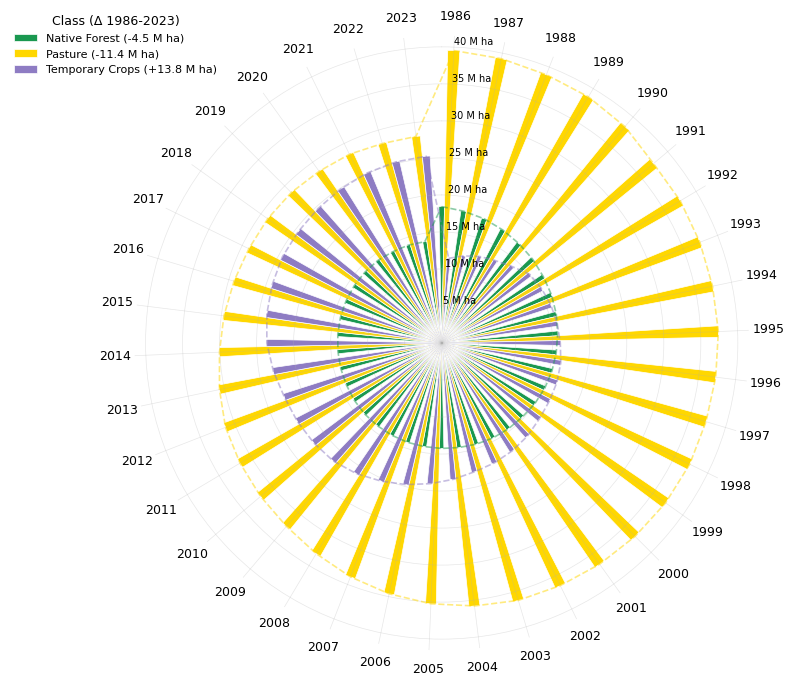

In [5]:
# Rename "Forest Formation" to "Native Forest" in value_name
histogram_table_study["value_name"] = histogram_table_study["value_name"].replace(
    "Forest Formation", "Native Forest"
)

# --- Select only the APAF_studyarea shapefile for the circular bar plot ---
#histogram_table_study = combined[combined["shapefile"] == "APAF_studyarea"].copy()
# Rename "Forest Formation" to "Native Forest" in value_name


# ============================================================
# Circular (polar) bar plot — APAF_studyarea only
# ============================================================

classes_to_plot = ["Native Forest",  "Pasture", "Temporary Crops"]  #"Forest Plantation",- edit as needed

# Extract year from filename, e.g. "Reclass_img_2020_v0806.tif" -> 2020
histogram_table_study["year"] = histogram_table_study["file"].str.extract(r"Reclass_img_(\d{4})_v0806\.tif")
histogram_table_study["year"] = histogram_table_study["year"].astype(int)

# Case-insensitive filter
mask = histogram_table_study["value_name"].str.lower().isin([c.lower() for c in classes_to_plot])
plot_df = histogram_table_study[mask].copy()

# Remove year 2024
plot_df = plot_df[plot_df["year"] != 1985]
plot_df = plot_df[plot_df["year"] != 2024]

# Pivot: rows = year, columns = class, values = area_mha
pivot_df = plot_df.pivot_table(index="year", columns="value_name", values="area_mha", aggfunc="sum").fillna(0)

# Reorder columns to match desired order
ordered_cols = [col for c in classes_to_plot for col in pivot_df.columns if col.lower() == c.lower()]
pivot_df = pivot_df[ordered_cols]

years = pivot_df.index.astype(int)
years_str = years.astype(str)
n_years = len(years)
n_classes = len(pivot_df.columns)

# Colors in column order (fallback to tab10 if not specified)
colors = [class_colors.get(col, plt.cm.tab10(i % 10)) for i, col in enumerate(pivot_df.columns)]

# Angle for each year group, evenly spaced around the circle
group_angle = 2 * np.pi / n_years
bar_width = group_angle / (n_classes + 1)

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": "polar"})
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# Plot bars and trend lines for each class
for i, col in enumerate(pivot_df.columns):
    angles = np.array([y * group_angle + i * bar_width for y in range(n_years)])
    values = pivot_df[col].values

    ax.bar(
        angles, values, width=bar_width, color=colors[i],
        edgecolor="white", linewidth=0.5, label=col, bottom=0
    )

    trend_angles = np.append(angles, angles[0])
    trend_values = np.append(values, values[0])
    ax.plot(trend_angles, trend_values, color=colors[i], linewidth=1.2, alpha=0.5, linestyle="--")

# X-axis (angle) ticks labeled with years
group_centers = np.array([y * group_angle + (n_classes - 1) * bar_width / 2 for y in range(n_years)])
ax.set_xticks(group_centers)
ax.set_xticklabels(years_str, fontsize=9)


# --- Minimal styling ---
ax.spines["polar"].set_visible(False)   # remove outer circle border
ax.set_ylabel("")
ax.grid(alpha=0.3, linewidth=0.5)       # keep faint gridlines, thinner
ax.set_title("", fontsize=12, pad=15)

# Show radial ticks with units, positioned along one angle so they don't clutter the circle
ax.set_rlabel_position(group_centers[0] * 180 / np.pi)  # align radial labels with first year group
ax.set_yticklabels([f"{tick:.0f} M ha" for tick in ax.get_yticks()], fontsize=7, color="black")

# Compute area difference between last year (2023) and first year (1985) for each class
diff_dict = {}
for col in pivot_df.columns:
    val_1986 = pivot_df.loc[1986, col] if 1986 in pivot_df.index else np.nan
    val_2023 = pivot_df.loc[2023, col] if 2023 in pivot_df.index else np.nan
    diff_dict[col] = val_2023 - val_1986

# Build legend labels including the difference, e.g. "Forest Formation (-12.4 M ha)"
legend_labels = [
    f"{col} ({diff_dict[col]:+.1f} M ha)" for col in pivot_df.columns
]

# Legend without frame, close to the plot, now with diff info
handles, _ = ax.get_legend_handles_labels()
ax.legend(
    handles,
    legend_labels,
    title="Class (Δ 1986-2023)",
    loc="upper right",
    bbox_to_anchor=(0.15, 1.05),
    frameon=False,
    fontsize=8,
    title_fontsize=9,
)

plt.tight_layout()
#plt.savefig(folder / "landcover_circular_bar_by_year_studyarea.png", dpi=300, bbox_inches="tight")
plt.show()

C:\Users\ahuvi\AppData\Local\Temp\ipykernel_29908\3323321569.py:80: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f"{tick:.0f} M ha" for tick in ax.get_yticks()], fontsize=7, color="black")


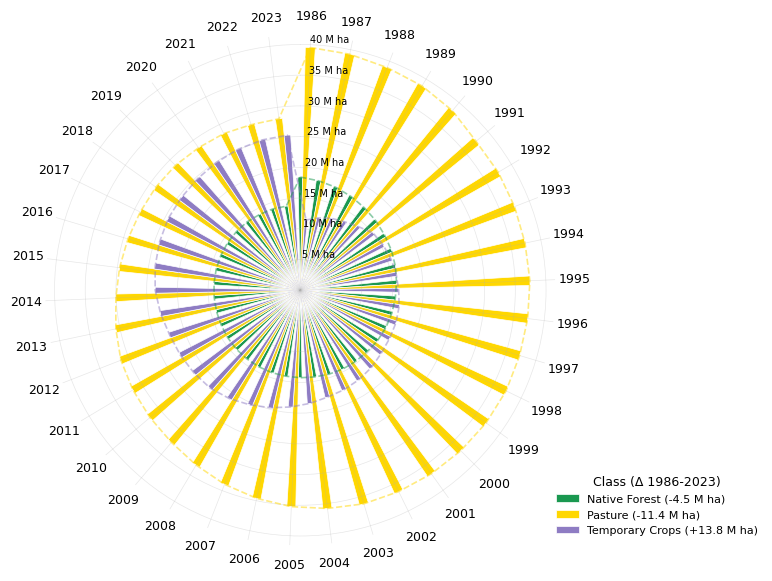

In [6]:
# Rename "Forest Formation" to "Native Forest" in value_name
histogram_table_study["value_name"] = histogram_table_study["value_name"].replace(
    "Forest Formation", "Native Forest"
)

# --- Select only the APAF_studyarea shapefile for the circular bar plot ---
#histogram_table_study = combined[combined["shapefile"] == "APAF_studyarea"].copy()
# Rename "Forest Formation" to "Native Forest" in value_name


# ============================================================
# Circular (polar) bar plot — APAF_studyarea only
# ============================================================

classes_to_plot = ["Native Forest",  "Pasture", "Temporary Crops"]  # "Forest Plantation",- edit as needed

# Extract year from filename, e.g. "Reclass_img_2020_v0806.tif" -> 2020
histogram_table_study["year"] = histogram_table_study["file"].str.extract(r"Reclass_img_(\d{4})_v0806\.tif")
histogram_table_study["year"] = histogram_table_study["year"].astype(int)

# Case-insensitive filter
mask = histogram_table_study["value_name"].str.lower().isin([c.lower() for c in classes_to_plot])
plot_df = histogram_table_study[mask].copy()

# Remove year 2024
plot_df = plot_df[plot_df["year"] != 1985]
plot_df = plot_df[plot_df["year"] != 2024]

# Pivot: rows = year, columns = class, values = area_mha
pivot_df = plot_df.pivot_table(index="year", columns="value_name", values="area_mha", aggfunc="sum").fillna(0)

# Reorder columns to match desired order
ordered_cols = [col for c in classes_to_plot for col in pivot_df.columns if col.lower() == c.lower()]
pivot_df = pivot_df[ordered_cols]

years = pivot_df.index.astype(int)
years_str = years.astype(str)
n_years = len(years)
n_classes = len(pivot_df.columns)

# Colors in column order (fallback to tab10 if not specified)
colors = [class_colors.get(col, plt.cm.tab10(i % 10)) for i, col in enumerate(pivot_df.columns)]

# Angle for each year group, evenly spaced around the circle
group_angle = 2 * np.pi / n_years
bar_width = group_angle / (n_classes + 1)

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": "polar"})
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# Plot bars and trend lines for each class
for i, col in enumerate(pivot_df.columns):
    angles = np.array([y * group_angle + i * bar_width for y in range(n_years)])
    values = pivot_df[col].values

    ax.bar(
        angles, values, width=bar_width, color=colors[i],
        edgecolor="white", linewidth=0.5, label=col, bottom=0
    )

    trend_angles = np.append(angles, angles[0])
    trend_values = np.append(values, values[0])
    ax.plot(trend_angles, trend_values, color=colors[i], linewidth=1.2, alpha=0.5, linestyle="--")

# X-axis (angle) ticks labeled with years
group_centers = np.array([y * group_angle + (n_classes - 1) * bar_width / 2 for y in range(n_years)])
ax.set_xticks(group_centers)
ax.set_xticklabels(years_str, fontsize=9)


# --- Minimal styling ---
ax.spines["polar"].set_visible(False)   # remove outer circle border
ax.set_ylabel("")
ax.grid(alpha=0.3, linewidth=0.5)       # keep faint gridlines, thinner
ax.set_title("", fontsize=12, pad=15)

# Show radial ticks with units, positioned along one angle so they don't clutter the circle
ax.set_rlabel_position(group_centers[0] * 180 / np.pi)  # align radial labels with first year group
ax.set_yticklabels([f"{tick:.0f} M ha" for tick in ax.get_yticks()], fontsize=7, color="black")

# Compute area difference between last year (2023) and first year (1985) for each class
diff_dict = {}
for col in pivot_df.columns:
    val_1986 = pivot_df.loc[1986, col] if 1986 in pivot_df.index else np.nan
    val_2023 = pivot_df.loc[2023, col] if 2023 in pivot_df.index else np.nan
    diff_dict[col] = val_2023 - val_1986

# Build legend labels including the difference, e.g. "Forest Formation (-12.4 M ha)"
legend_labels = [
    f"{col} ({diff_dict[col]:+.1f} M ha)" for col in pivot_df.columns
]

# Legend without frame, close to the plot, now with diff info
handles, _ = ax.get_legend_handles_labels()
ax.legend(
    handles,
    legend_labels,
    title="Class (Δ 1986-2023)",
    loc="lower center",
    bbox_to_anchor=(1.2, -0),
    frameon=False,
    fontsize=8,
    title_fontsize=9,
)

plt.tight_layout()
#plt.savefig(folder / "landcover_circular_bar_by_year_studyarea.png", dpi=300, bbox_inches="tight")
plt.show()

## APAF ecoregion

C:\Users\ahuvi\AppData\Local\Temp\ipykernel_29908\589284744.py:83: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f"{tick:.0f} M ha" for tick in ax.get_yticks()], fontsize=7, color="black")


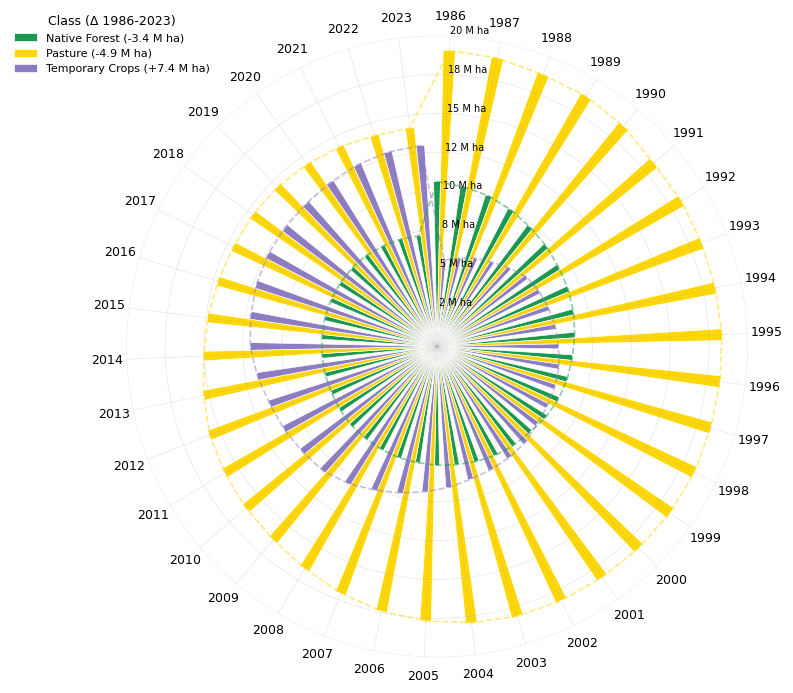

In [7]:
# Folder containing the CSV
folder = Path(r"C:\Users\")
# CSV file name
csv_path_study = folder / "histograms_long_APAF_ecoregion_with_area_pct.csv"
# Read the CSV
histogram_table_study = pd.read_csv(csv_path_study)


# --- Select only the APAF_studyarea shapefile for the circular bar plot ---
#histogram_table_study = combined[combined["shapefile"] == "APAF_ecoregion"].copy()
histogram_table_study["value_name"] = histogram_table_study["value_name"].replace(
    "Forest Formation", "Native Forest"
)
# ============================================================
# Circular (polar) bar plot — APAF_ecoregion only
# ============================================================

classes_to_plot = ["Native Forest", "Pasture", "Temporary Crops"]  #"Forest Plantation", - edit as needed

# Extract year from filename, e.g. "Reclass_img_2020_v0806.tif" -> 2020
histogram_table_study["year"] = histogram_table_study["file"].str.extract(r"Reclass_img_(\d{4})_v0806\.tif")
histogram_table_study["year"] = histogram_table_study["year"].astype(int)

# Case-insensitive filter
mask = histogram_table_study["value_name"].str.lower().isin([c.lower() for c in classes_to_plot])
plot_df = histogram_table_study[mask].copy()

# Remove year 2024
plot_df = plot_df[plot_df["year"] != 1985]
plot_df = plot_df[plot_df["year"] != 2024]

# Pivot: rows = year, columns = class, values = area_mha
pivot_df = plot_df.pivot_table(index="year", columns="value_name", values="area_mha", aggfunc="sum").fillna(0)

# Reorder columns to match desired order
ordered_cols = [col for c in classes_to_plot for col in pivot_df.columns if col.lower() == c.lower()]
pivot_df = pivot_df[ordered_cols]

years = pivot_df.index.astype(int)
years_str = years.astype(str)
n_years = len(years)
n_classes = len(pivot_df.columns)

# Colors in column order (fallback to tab10 if not specified)
colors = [class_colors.get(col, plt.cm.tab10(i % 10)) for i, col in enumerate(pivot_df.columns)]

# Angle for each year group, evenly spaced around the circle
group_angle = 2 * np.pi / n_years
bar_width = group_angle / (n_classes + 1)

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": "polar"})
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# Plot bars and trend lines for each class
for i, col in enumerate(pivot_df.columns):
    angles = np.array([y * group_angle + i * bar_width for y in range(n_years)])
    values = pivot_df[col].values

    ax.bar(
        angles, values, width=bar_width, color=colors[i],
        edgecolor="white", linewidth=0.5, label=col, bottom=0
    )

    trend_angles = np.append(angles, angles[0])
    trend_values = np.append(values, values[0])
    ax.plot(trend_angles, trend_values, color=colors[i], linewidth=1.2, alpha=0.5, linestyle="--")

# X-axis (angle) ticks labeled with years
group_centers = np.array([y * group_angle + (n_classes - 1) * bar_width / 2 for y in range(n_years)])
ax.set_xticks(group_centers)
ax.set_xticklabels(years_str, fontsize=9)


# --- Minimal styling ---
ax.spines["polar"].set_visible(False)   # remove outer circle border
ax.set_ylabel("")
ax.grid(alpha=0.3, linewidth=0.5)       # keep faint gridlines, thinner
ax.set_title("", fontsize=12, pad=15)

# Show radial ticks with units, positioned along one angle so they don't clutter the circle
ax.set_rlabel_position(group_centers[0] * 180 / np.pi)  # align radial labels with first year group
ax.set_yticklabels([f"{tick:.0f} M ha" for tick in ax.get_yticks()], fontsize=7, color="black")

# Compute area difference between last year (2023) and first year (1985) for each class
diff_dict = {}
for col in pivot_df.columns:
    val_1986 = pivot_df.loc[1986, col] if 1986 in pivot_df.index else np.nan
    val_2023 = pivot_df.loc[2023, col] if 2023 in pivot_df.index else np.nan
    diff_dict[col] = val_2023 - val_1986

# Build legend labels including the difference, e.g. "Forest Formation (-12.4 M ha)"
legend_labels = [
    f"{col} ({diff_dict[col]:+.1f} M ha)" for col in pivot_df.columns
]

# Legend without frame, close to the plot, now with diff info
handles, _ = ax.get_legend_handles_labels()
ax.legend(
    handles,
    legend_labels,
    title="Class (Δ 1986-2023)",
    loc="upper right",
    bbox_to_anchor=(0.15, 1.05),
    frameon=False,
    fontsize=8,
    title_fontsize=9,
)

plt.tight_layout()
#plt.savefig(folder / "landcover_circular_bar_by_year_studyarea.png", dpi=300, bbox_inches="tight")
plt.show()

## Argentina

C:\Users\ahuvi\AppData\Local\Temp\ipykernel_29908\4285724703.py:83: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f"{tick:.0f} M ha" for tick in ax.get_yticks()], fontsize=7, color="black")


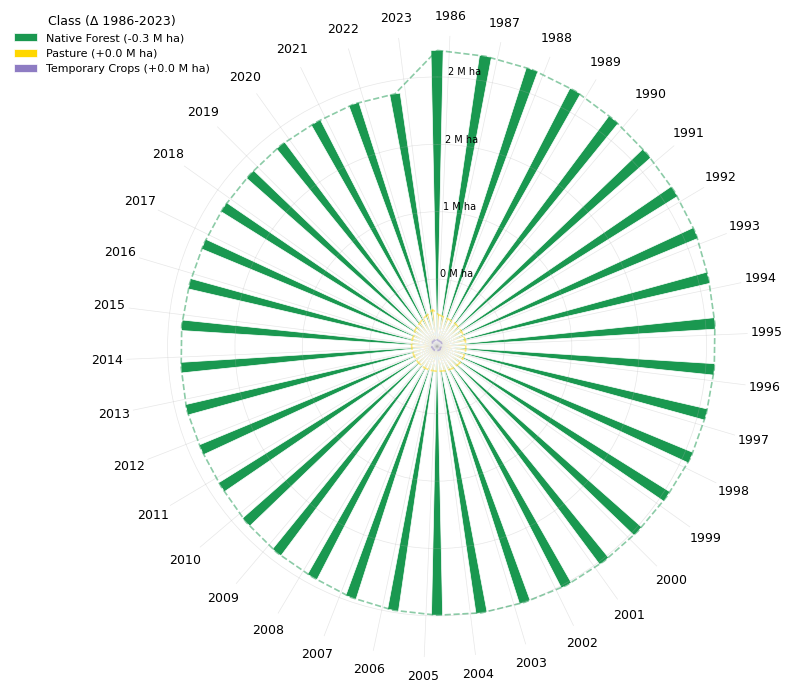

In [8]:
# Folder containing the CSV
folder = Path(r"C:\Users\")
# CSV file name
csv_path_study = folder / "histograms_long_Argentina_with_area_pct.csv"
# Read the CSV
histogram_table_study = pd.read_csv(csv_path_study)


# --- Select only the APAF_studyarea shapefile for the circular bar plot ---
#histogram_table_study = combined[combined["shapefile"] == "Argentina"].copy()
histogram_table_study["value_name"] = histogram_table_study["value_name"].replace(
    "Forest Formation", "Native Forest"
)
# ============================================================
# Circular (polar) bar plot — Argentina
# ============================================================

classes_to_plot = ["Native Forest", "Pasture", "Temporary Crops"]  #"Forest Plantation", - edit as needed

# Extract year from filename, e.g. "Reclass_img_2020_v0806.tif" -> 2020
histogram_table_study["year"] = histogram_table_study["file"].str.extract(r"Reclass_img_(\d{4})_v0806\.tif")
histogram_table_study["year"] = histogram_table_study["year"].astype(int)

# Case-insensitive filter
mask = histogram_table_study["value_name"].str.lower().isin([c.lower() for c in classes_to_plot])
plot_df = histogram_table_study[mask].copy()

# Remove year 2024
plot_df = plot_df[plot_df["year"] != 1985]
plot_df = plot_df[plot_df["year"] != 2024]

# Pivot: rows = year, columns = class, values = area_mha
pivot_df = plot_df.pivot_table(index="year", columns="value_name", values="area_mha", aggfunc="sum").fillna(0)

# Reorder columns to match desired order
ordered_cols = [col for c in classes_to_plot for col in pivot_df.columns if col.lower() == c.lower()]
pivot_df = pivot_df[ordered_cols]

years = pivot_df.index.astype(int)
years_str = years.astype(str)
n_years = len(years)
n_classes = len(pivot_df.columns)

# Colors in column order (fallback to tab10 if not specified)
colors = [class_colors.get(col, plt.cm.tab10(i % 10)) for i, col in enumerate(pivot_df.columns)]

# Angle for each year group, evenly spaced around the circle
group_angle = 2 * np.pi / n_years
bar_width = group_angle / (n_classes + 1)

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": "polar"})
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# Plot bars and trend lines for each class
for i, col in enumerate(pivot_df.columns):
    angles = np.array([y * group_angle + i * bar_width for y in range(n_years)])
    values = pivot_df[col].values

    ax.bar(
        angles, values, width=bar_width, color=colors[i],
        edgecolor="white", linewidth=0.5, label=col, bottom=0
    )

    trend_angles = np.append(angles, angles[0])
    trend_values = np.append(values, values[0])
    ax.plot(trend_angles, trend_values, color=colors[i], linewidth=1.2, alpha=0.5, linestyle="--")

# X-axis (angle) ticks labeled with years
group_centers = np.array([y * group_angle + (n_classes - 1) * bar_width / 2 for y in range(n_years)])
ax.set_xticks(group_centers)
ax.set_xticklabels(years_str, fontsize=9)


# --- Minimal styling ---
ax.spines["polar"].set_visible(False)   # remove outer circle border
ax.set_ylabel("")
ax.grid(alpha=0.3, linewidth=0.5)       # keep faint gridlines, thinner
ax.set_title("", fontsize=12, pad=15)

# Show radial ticks with units, positioned along one angle so they don't clutter the circle
ax.set_rlabel_position(group_centers[0] * 180 / np.pi)  # align radial labels with first year group
ax.set_yticklabels([f"{tick:.0f} M ha" for tick in ax.get_yticks()], fontsize=7, color="black")

# Compute area difference between last year (2023) and first year (1985) for each class
diff_dict = {}
for col in pivot_df.columns:
    val_1986 = pivot_df.loc[1986, col] if 1986 in pivot_df.index else np.nan
    val_2023 = pivot_df.loc[2023, col] if 2023 in pivot_df.index else np.nan
    diff_dict[col] = val_2023 - val_1986

# Build legend labels including the difference, e.g. "Forest Formation (-12.4 M ha)"
legend_labels = [
    f"{col} ({diff_dict[col]:+.1f} M ha)" for col in pivot_df.columns
]

# Legend without frame, close to the plot, now with diff info
handles, _ = ax.get_legend_handles_labels()
ax.legend(
    handles,
    legend_labels,
    title="Class (Δ 1986-2023)",
    loc="upper right",
    bbox_to_anchor=(0.15, 1.05),
    frameon=False,
    fontsize=8,
    title_fontsize=9,
)

plt.tight_layout()
#plt.savefig(folder / "landcover_circular_bar_by_year_studyarea.png", dpi=300, bbox_inches="tight")
plt.show()

## Brazil

C:\Users\ahuvi\AppData\Local\Temp\ipykernel_29908\634045559.py:82: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f"{tick:.0f} M ha" for tick in ax.get_yticks()], fontsize=7, color="black")


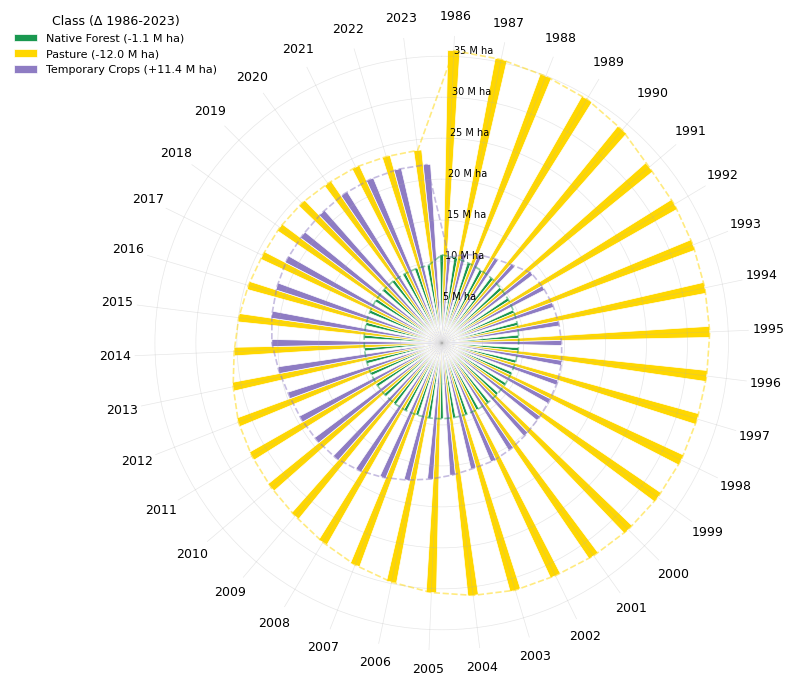

In [9]:
# Folder containing the CSV
folder = Path(r"C:\Users\")
# CSV file name
csv_path_study = folder / "histograms_long_Brazil_with_area_pct.csv"
# Read the CSV
histogram_table_study = pd.read_csv(csv_path_study)

# --- Select only the APAF_studyarea shapefile for the circular bar plot ---
#histogram_table_study = combined[combined["shapefile"] == "Brazil"].copy()
histogram_table_study["value_name"] = histogram_table_study["value_name"].replace(
    "Forest Formation", "Native Forest"
)
# ============================================================
# Circular (polar) bar plot — Brazil
# ============================================================

classes_to_plot = ["Native Forest", "Pasture", "Temporary Crops"]  #"Forest Plantation", - edit as needed

# Extract year from filename, e.g. "Reclass_img_2020_v0806.tif" -> 2020
histogram_table_study["year"] = histogram_table_study["file"].str.extract(r"Reclass_img_(\d{4})_v0806\.tif")
histogram_table_study["year"] = histogram_table_study["year"].astype(int)

# Case-insensitive filter
mask = histogram_table_study["value_name"].str.lower().isin([c.lower() for c in classes_to_plot])
plot_df = histogram_table_study[mask].copy()

# Remove year 2024
plot_df = plot_df[plot_df["year"] != 1985]
plot_df = plot_df[plot_df["year"] != 2024]

# Pivot: rows = year, columns = class, values = area_mha
pivot_df = plot_df.pivot_table(index="year", columns="value_name", values="area_mha", aggfunc="sum").fillna(0)

# Reorder columns to match desired order
ordered_cols = [col for c in classes_to_plot for col in pivot_df.columns if col.lower() == c.lower()]
pivot_df = pivot_df[ordered_cols]

years = pivot_df.index.astype(int)
years_str = years.astype(str)
n_years = len(years)
n_classes = len(pivot_df.columns)

# Colors in column order (fallback to tab10 if not specified)
colors = [class_colors.get(col, plt.cm.tab10(i % 10)) for i, col in enumerate(pivot_df.columns)]

# Angle for each year group, evenly spaced around the circle
group_angle = 2 * np.pi / n_years
bar_width = group_angle / (n_classes + 1)

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": "polar"})
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# Plot bars and trend lines for each class
for i, col in enumerate(pivot_df.columns):
    angles = np.array([y * group_angle + i * bar_width for y in range(n_years)])
    values = pivot_df[col].values

    ax.bar(
        angles, values, width=bar_width, color=colors[i],
        edgecolor="white", linewidth=0.5, label=col, bottom=0
    )

    trend_angles = np.append(angles, angles[0])
    trend_values = np.append(values, values[0])
    ax.plot(trend_angles, trend_values, color=colors[i], linewidth=1.2, alpha=0.5, linestyle="--")

# X-axis (angle) ticks labeled with years
group_centers = np.array([y * group_angle + (n_classes - 1) * bar_width / 2 for y in range(n_years)])
ax.set_xticks(group_centers)
ax.set_xticklabels(years_str, fontsize=9)


# --- Minimal styling ---
ax.spines["polar"].set_visible(False)   # remove outer circle border
ax.set_ylabel("")
ax.grid(alpha=0.3, linewidth=0.5)       # keep faint gridlines, thinner
ax.set_title("", fontsize=12, pad=15)

# Show radial ticks with units, positioned along one angle so they don't clutter the circle
ax.set_rlabel_position(group_centers[0] * 180 / np.pi)  # align radial labels with first year group
ax.set_yticklabels([f"{tick:.0f} M ha" for tick in ax.get_yticks()], fontsize=7, color="black")

# Compute area difference between last year (2023) and first year (1985) for each class
diff_dict = {}
for col in pivot_df.columns:
    val_1986 = pivot_df.loc[1986, col] if 1986 in pivot_df.index else np.nan
    val_2023 = pivot_df.loc[2023, col] if 2023 in pivot_df.index else np.nan
    diff_dict[col] = val_2023 - val_1986

# Build legend labels including the difference, e.g. "Forest Formation (-12.4 M ha)"
legend_labels = [
    f"{col} ({diff_dict[col]:+.1f} M ha)" for col in pivot_df.columns
]

# Legend without frame, close to the plot, now with diff info
handles, _ = ax.get_legend_handles_labels()
ax.legend(
    handles,
    legend_labels,
    title="Class (Δ 1986-2023)",
    loc="upper right",
    bbox_to_anchor=(0.15, 1.05),
    frameon=False,
    fontsize=8,
    title_fontsize=9,
)

plt.tight_layout()
#plt.savefig(folder / "landcover_circular_bar_by_year_studyarea.png", dpi=300, bbox_inches="tight")
plt.show()

## Paraguay

C:\Users\ahuvi\AppData\Local\Temp\ipykernel_29908\4140411886.py:82: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f"{tick:.0f} M ha" for tick in ax.get_yticks()], fontsize=7, color="black")


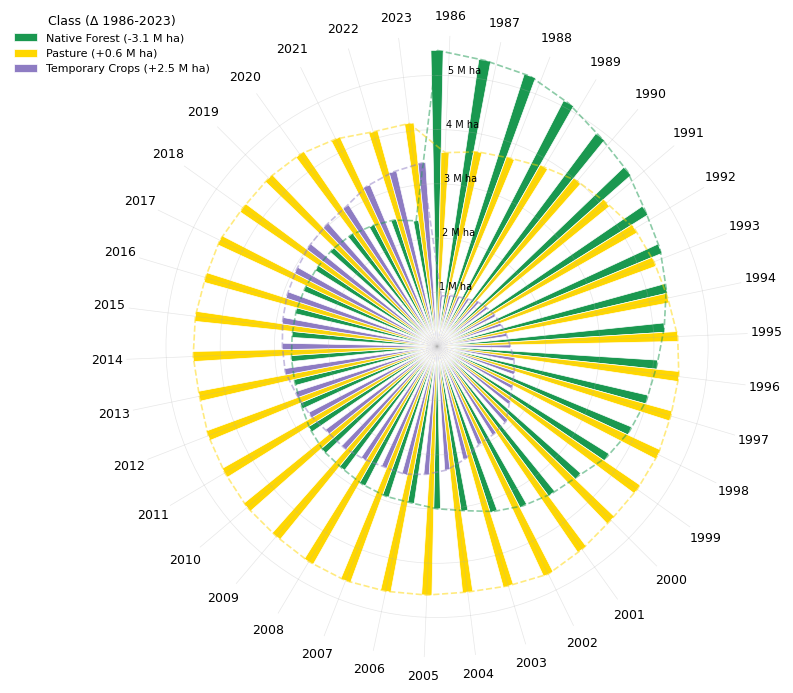

In [10]:
# Folder containing the CSV
folder = Path(r"C:\Users\")
# CSV file name
csv_path_study = folder / "histograms_long_Paraguay_with_area_pct.csv"
# Read the CSV
histogram_table_study = pd.read_csv(csv_path_study)

# --- Select only the APAF_studyarea shapefile for the circular bar plot ---
#histogram_table_study = combined[combined["shapefile"] == "Paraguay"].copy()
histogram_table_study["value_name"] = histogram_table_study["value_name"].replace(
    "Forest Formation", "Native Forest"
)
# ============================================================
# Circular (polar) bar plot — Paraguay
# ============================================================

classes_to_plot = ["Native Forest", "Pasture", "Temporary Crops"]  #"Forest Plantation", - edit as needed

# Extract year from filename, e.g. "Reclass_img_2020_v0806.tif" -> 2020
histogram_table_study["year"] = histogram_table_study["file"].str.extract(r"Reclass_img_(\d{4})_v0806\.tif")
histogram_table_study["year"] = histogram_table_study["year"].astype(int)

# Case-insensitive filter
mask = histogram_table_study["value_name"].str.lower().isin([c.lower() for c in classes_to_plot])
plot_df = histogram_table_study[mask].copy()

# Remove year 2024
plot_df = plot_df[plot_df["year"] != 1985]
plot_df = plot_df[plot_df["year"] != 2024]

# Pivot: rows = year, columns = class, values = area_mha
pivot_df = plot_df.pivot_table(index="year", columns="value_name", values="area_mha", aggfunc="sum").fillna(0)

# Reorder columns to match desired order
ordered_cols = [col for c in classes_to_plot for col in pivot_df.columns if col.lower() == c.lower()]
pivot_df = pivot_df[ordered_cols]

years = pivot_df.index.astype(int)
years_str = years.astype(str)
n_years = len(years)
n_classes = len(pivot_df.columns)

# Colors in column order (fallback to tab10 if not specified)
colors = [class_colors.get(col, plt.cm.tab10(i % 10)) for i, col in enumerate(pivot_df.columns)]

# Angle for each year group, evenly spaced around the circle
group_angle = 2 * np.pi / n_years
bar_width = group_angle / (n_classes + 1)

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": "polar"})
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# Plot bars and trend lines for each class
for i, col in enumerate(pivot_df.columns):
    angles = np.array([y * group_angle + i * bar_width for y in range(n_years)])
    values = pivot_df[col].values

    ax.bar(
        angles, values, width=bar_width, color=colors[i],
        edgecolor="white", linewidth=0.5, label=col, bottom=0
    )

    trend_angles = np.append(angles, angles[0])
    trend_values = np.append(values, values[0])
    ax.plot(trend_angles, trend_values, color=colors[i], linewidth=1.2, alpha=0.5, linestyle="--")

# X-axis (angle) ticks labeled with years
group_centers = np.array([y * group_angle + (n_classes - 1) * bar_width / 2 for y in range(n_years)])
ax.set_xticks(group_centers)
ax.set_xticklabels(years_str, fontsize=9)


# --- Minimal styling ---
ax.spines["polar"].set_visible(False)   # remove outer circle border
ax.set_ylabel("")
ax.grid(alpha=0.3, linewidth=0.5)       # keep faint gridlines, thinner
ax.set_title("", fontsize=12, pad=15)

# Show radial ticks with units, positioned along one angle so they don't clutter the circle
ax.set_rlabel_position(group_centers[0] * 180 / np.pi)  # align radial labels with first year group
ax.set_yticklabels([f"{tick:.0f} M ha" for tick in ax.get_yticks()], fontsize=7, color="black")

# Compute area difference between last year (2023) and first year (1985) for each class
diff_dict = {}
for col in pivot_df.columns:
    val_1986 = pivot_df.loc[1986, col] if 1986 in pivot_df.index else np.nan
    val_2023 = pivot_df.loc[2023, col] if 2023 in pivot_df.index else np.nan
    diff_dict[col] = val_2023 - val_1986

# Build legend labels including the difference, e.g. "Forest Formation (-12.4 M ha)"
legend_labels = [
    f"{col} ({diff_dict[col]:+.1f} M ha)" for col in pivot_df.columns
]

# Legend without frame, close to the plot, now with diff info
handles, _ = ax.get_legend_handles_labels()
ax.legend(
    handles,
    legend_labels,
    title="Class (Δ 1986-2023)",
    loc="upper right",
    bbox_to_anchor=(0.15, 1.05),
    frameon=False,
    fontsize=8,
    title_fontsize=9,
)

plt.tight_layout()
#plt.savefig(folder / "landcover_circular_bar_by_year_studyarea.png", dpi=300, bbox_inches="tight")
plt.show()

C:\Users\ahuvi\AppData\Local\Temp\ipykernel_29908\1229960826.py:98: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f"{tick:.0f} M ha" for tick in ax.get_yticks()], fontsize=7, color="black")


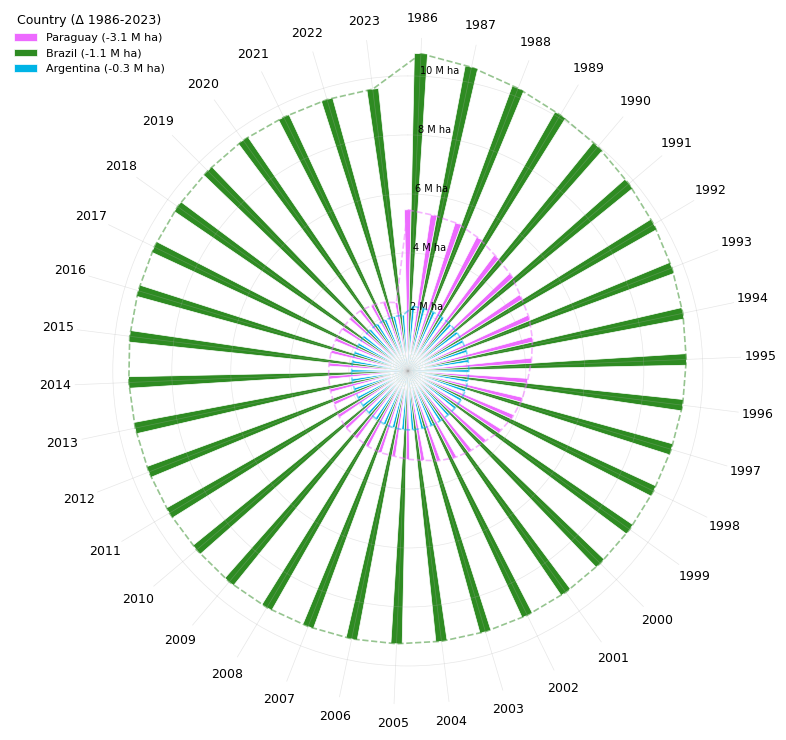

In [11]:
# Folder containing the CSVs
folder = Path(r"C:\Users\")

# --- Read all three country tables and tag each with its country ---
country_files = {
    "Paraguay": "histograms_long_Paraguay_with_area_pct.csv",
    "Brazil": "histograms_long_Brazil_with_area_pct.csv",
    "Argentina": "histograms_long_Argentina_with_area_pct.csv",
}

tables = []
for country, filename in country_files.items():
    df = pd.read_csv(folder / filename)
    df["value_name"] = df["value_name"].replace("Forest Formation", "Native Forest")
    df["country"] = country
    tables.append(df)

histogram_table_all = pd.concat(tables, ignore_index=True)

# ============================================================
# Circular (polar) bar plot — Native Forest, by country
# ============================================================

TARGET_CLASS = "Native Forest"

# Extract year from filename, e.g. "Reclass_img_2020_v0806.tif" -> 2020
histogram_table_all["year"] = histogram_table_all["file"].str.extract(r"Reclass_img_(\d{4})_v0806\.tif")
histogram_table_all["year"] = histogram_table_all["year"].astype(int)

# Case-insensitive filter to just Native Forest
mask = histogram_table_all["value_name"].str.lower() == TARGET_CLASS.lower()
plot_df = histogram_table_all[mask].copy()

# Remove years 1985 and 2024
plot_df = plot_df[plot_df["year"] != 1985]
plot_df = plot_df[plot_df["year"] != 2024]

# Pivot: rows = year, columns = country, values = area_mha
pivot_df = plot_df.pivot_table(index="year", columns="country", values="area_mha", aggfunc="sum").fillna(0)

# Order columns to match the order countries were read in above
ordered_cols = [c for c in country_files if c in pivot_df.columns]
pivot_df = pivot_df[ordered_cols]

years = pivot_df.index.astype(int)
years_str = years.astype(str)
n_years = len(years)
n_countries = len(pivot_df.columns)

# Colors per country (edit as needed)
country_colors = {
    "Paraguay": "#ED6AFF",
    "Brazil": "#2E8B22",
    "Argentina": "#00B4E6",
}
colors = [country_colors.get(col, plt.cm.tab10(i % 10)) for i, col in enumerate(pivot_df.columns)]

# Angle for each year group, evenly spaced around the circle
group_angle = 2 * np.pi / n_years
bar_width = group_angle / (n_countries + 1)

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": "polar"})
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# Plot bars and trend lines for each country
for i, col in enumerate(pivot_df.columns):
    angles = np.array([y * group_angle + i * bar_width for y in range(n_years)])
    values = pivot_df[col].values

    ax.bar(
        angles, values, width=bar_width, color=colors[i],
        edgecolor="white", linewidth=0.5, label=col, bottom=0
    )

    trend_angles = np.append(angles, angles[0])
    trend_values = np.append(values, values[0])
    ax.plot(trend_angles, trend_values, color=colors[i], linewidth=1.2, alpha=0.5, linestyle="--")

# X-axis (angle) ticks labeled with years
group_centers = np.array([y * group_angle + (n_countries - 1) * bar_width / 2 for y in range(n_years)])
ax.set_xticks(group_centers)
ax.set_xticklabels(years_str, fontsize=9)

# --- Minimal styling ---
ax.spines["polar"].set_visible(False)   # remove outer circle border
ax.set_ylabel("")
ax.grid(alpha=0.3, linewidth=0.5)       # keep faint gridlines, thinner
#ax.set_title(f"{TARGET_CLASS} by year and country", fontsize=12, pad=15)

# Show radial ticks with units, positioned along one angle so they don't clutter the circle
ax.set_rlabel_position(group_centers[0] * 180 / np.pi)  # align radial labels with first year group
ax.set_yticklabels([f"{tick:.0f} M ha" for tick in ax.get_yticks()], fontsize=7, color="black")

# Compute area difference between last year (2023) and first year (1986) for each country
diff_dict = {}
for col in pivot_df.columns:
    val_1986 = pivot_df.loc[1986, col] if 1986 in pivot_df.index else np.nan
    val_2023 = pivot_df.loc[2023, col] if 2023 in pivot_df.index else np.nan
    diff_dict[col] = val_2023 - val_1986

# Build legend labels including the difference, e.g. "Brazil (-12.4 M ha)"
legend_labels = [
    f"{col} ({diff_dict[col]:+.1f} M ha)" for col in pivot_df.columns
]

# Legend without frame, close to the plot, now with diff info
handles, _ = ax.get_legend_handles_labels()
ax.legend(
    handles,
    legend_labels,
    title="Country (Δ 1986-2023)",
    loc="upper right",
    bbox_to_anchor=(0.15, 1.05),
    frameon=False,
    fontsize=8,
    title_fontsize=9,
)

plt.tight_layout()
#plt.savefig(folder / "native_forest_circular_bar_by_year_country.png", dpi=300, bbox_inches="tight")
plt.show()

C:\Users\ahuvi\AppData\Local\Temp\ipykernel_29908\1068212993.py:111: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f"{tick:.0f}%" for tick in ax.get_yticks()], fontsize=7, color="black")


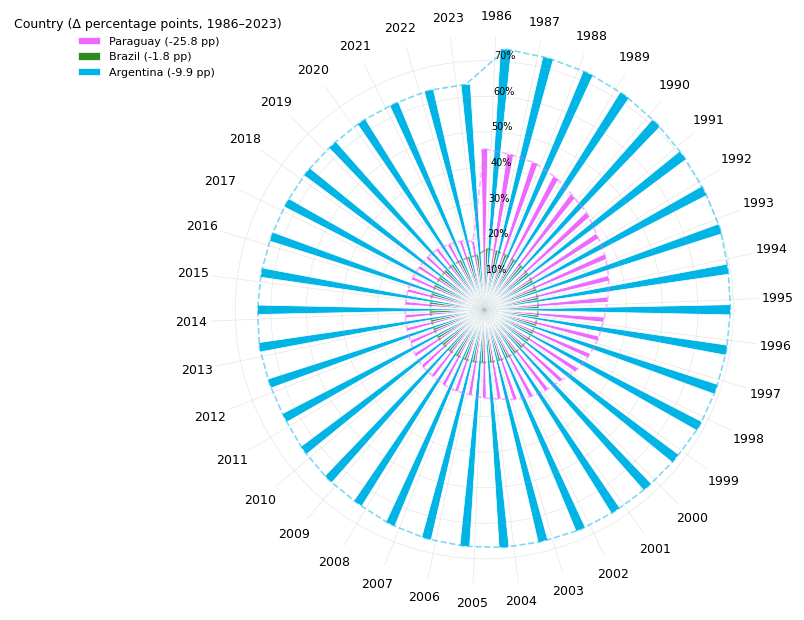

In [12]:
# Folder containing the CSVs
folder = Path(r"C:\Users\")

# --- Read all three country tables and tag each with its country ---
country_files = {
    "Paraguay": "histograms_long_Paraguay_with_area_pct.csv",
    "Brazil": "histograms_long_Brazil_with_area_pct.csv",
    "Argentina": "histograms_long_Argentina_with_area_pct.csv",
}

tables = []
for country, filename in country_files.items():
    df = pd.read_csv(folder / filename)
    df["value_name"] = df["value_name"].replace("Forest Formation", "Native Forest")
    df["country"] = country
    tables.append(df)

histogram_table_all = pd.concat(tables, ignore_index=True)

# ============================================================
# Circular (polar) bar plot — Native Forest, by country
# ============================================================

TARGET_CLASS = "Native Forest"

# Extract year from filename, e.g. "Reclass_img_2020_v0806.tif" -> 2020
histogram_table_all["year"] = histogram_table_all["file"].str.extract(r"Reclass_img_(\d{4})_v0806\.tif")
histogram_table_all["year"] = histogram_table_all["year"].astype(int)

# Case-insensitive filter to just Native Forest
mask = histogram_table_all["value_name"].str.lower() == TARGET_CLASS.lower()
plot_df = histogram_table_all[mask].copy()

# Remove years 1985 and 2024
plot_df = plot_df[plot_df["year"] != 1985]
plot_df = plot_df[plot_df["year"] != 2024]

# Pivot: rows = year, columns = country, values = area_mha
pivot_df = plot_df.pivot_table(index="year", columns="country", values="area_mha", aggfunc="sum").fillna(0)

# Order columns to match the order countries were read in above
ordered_cols = [c for c in country_files if c in pivot_df.columns]
pivot_df = pivot_df[ordered_cols]

# --- Convert to percentage of each country's total study area ---
COUNTRY_TOTAL_AREA_MHA = {
    "Brazil": 62.3931,
    "Argentina": 2.9913,
    "Paraguay": 12.0780,
}
for col in pivot_df.columns:
    total = COUNTRY_TOTAL_AREA_MHA.get(col)
    if total:
        pivot_df[col] = pivot_df[col] / total * 100
    else:
        print(f"Warning: no total area defined for '{col}' — left as area_mha, not percentage")

years = pivot_df.index.astype(int)
years_str = years.astype(str)
n_years = len(years)
n_countries = len(pivot_df.columns)

# Colors per country (edit as needed)
country_colors = {
    "Paraguay": "#ED6AFF",
    "Brazil": "#2E8B22",
    "Argentina": "#00B4E6",
}
colors = [country_colors.get(col, plt.cm.tab10(i % 10)) for i, col in enumerate(pivot_df.columns)]

# Angle for each year group, evenly spaced around the circle
group_angle = 2 * np.pi / n_years
bar_width = group_angle / (n_countries + 1)

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": "polar"})
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# Plot bars and trend lines for each country
for i, col in enumerate(pivot_df.columns):
    angles = np.array([y * group_angle + i * bar_width for y in range(n_years)])
    values = pivot_df[col].values

    ax.bar(
        angles, values, width=bar_width, color=colors[i],
        edgecolor="white", linewidth=0.5, label=col, bottom=0
    )

    trend_angles = np.append(angles, angles[0])
    trend_values = np.append(values, values[0])
    ax.plot(trend_angles, trend_values, color=colors[i], linewidth=1.2, alpha=0.5, linestyle="--")

# X-axis (angle) ticks labeled with years
group_centers = np.array([y * group_angle + (n_countries - 1) * bar_width / 2 for y in range(n_years)])
ax.set_xticks(group_centers)
ax.set_xticklabels(years_str, fontsize=9)

# --- Minimal styling ---
ax.spines["polar"].set_visible(False)   # remove outer circle border
ax.set_ylabel("")
ax.grid(alpha=0.3, linewidth=0.5)       # keep faint gridlines, thinner
#ax.set_title(f"{TARGET_CLASS} by year and country", fontsize=12, pad=15)

# Show radial ticks with units, positioned along one angle so they don't clutter the circle
ax.set_rlabel_position(group_centers[0] * 180 / np.pi)  # align radial labels with first year group
ax.set_yticklabels([f"{tick:.0f}%" for tick in ax.get_yticks()], fontsize=7, color="black")

# Compute the change in percentage points between the last year (2023) and
# first year (1986) for each country
diff_dict = {}
for col in pivot_df.columns:
    val_1986 = pivot_df.loc[1986, col] if 1986 in pivot_df.index else np.nan
    val_2023 = pivot_df.loc[2023, col] if 2023 in pivot_df.index else np.nan
    diff_dict[col] = val_2023 - val_1986

# Build legend labels including the change, e.g. "Brazil (-3.2 pp)"
legend_labels = [
    f"{col} ({diff_dict[col]:+.1f} pp)" for col in pivot_df.columns
]

# Legend without frame, close to the plot, now with diff info
handles, _ = ax.get_legend_handles_labels()
ax.legend(
    handles,
    legend_labels,
    title="Country (Δ percentage points, 1986–2023)",
    loc="upper right",
    bbox_to_anchor=(0.15, 1.05),
    frameon=False,
    fontsize=8,
    title_fontsize=9,
)

plt.tight_layout()
#plt.savefig(folder / "native_forest_circular_bar_by_year_country.png", dpi=300, bbox_inches="tight")
plt.show()